In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('/content/train.csv')
print(df.head(10))
print("Dataset Shape:", df.shape)

   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   
5   6          50       RL         85.0    14115   Pave   NaN      IR1   
6   7          20       RL         75.0    10084   Pave   NaN      Reg   
7   8          60       RL          NaN    10382   Pave   NaN      IR1   
8   9          50       RM         51.0     6120   Pave   NaN      Reg   
9  10         190       RL         50.0     7420   Pave   NaN      Reg   

  LandContour Utilities  ... PoolArea PoolQC  Fence MiscFeature MiscVal  \
0         Lvl    AllPub  ...        0    NaN    NaN         NaN       0   
1         Lvl    AllPub  ...       

In [ ]:
#Select features
features = [
    'GrLivArea',
    'BedroomAbvGr',
    'FullBath',
    'OverallQual',
    'YearBuilt'
]
#Select target variable
target = 'SalePrice'
X = df[features]
y = df[target]
print("Features:")
display(X.head())
print("Target:")
display(y.head())

Features:


,GrLivArea,BedroomAbvGr,FullBath,OverallQual,YearBuilt
0,1710,3,2,7,2003
1,1262,3,2,6,1976
2,1786,3,2,7,2001
3,1717,3,1,7,1915
4,2198,4,2,8,2000


Target:


,SalePrice
0,208500
1,181500
2,223500
3,140000
4,250000


In [ ]:
print("Missing values in each feature:")
print(X.isnull().sum())
print("\nMissing values in target:")
print(y.isnull().sum())

Missing values in each feature:
GrLivArea       0
BedroomAbvGr    0
FullBath        0
OverallQual     0
YearBuilt       0
dtype: int64

Missing values in target:
0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# Remove rows with missing target values
data = df[features + [target]].dropna(subset=[target])

# Separate features and target
X = data[features]
y = data[target]

# Different test sizes
split_ratios = [0.2, 0.3, 0.4]

results = []

for test_size in split_ratios:

    # Split data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42
    )

    # Create preprocessing and regression pipeline
    model = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('regressor', LinearRegression())
    ])

    # Train the model
    model.fit(X_train, y_train)

    # Predict house prices
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    r2 = r2_score(y_test, y_pred)

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    # Store results
    results.append({
        'Train Size': f'{int((1-test_size) * 100)}%',
        'Test Size': f'{int(test_size * 100)}%',
        'R2 Score': r2,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse
    })

# Display results
results_df = pd.DataFrame(results)

print("Linear Regression Results:")
display(results_df.round(2))

Linear Regression Results:


,Train Size,Test Size,R2 Score,MAE,MSE,RMSE
0,80%,20%,0.77,27820.40,1.754890e+09,41891.41
1,70%,30%,0.78,26832.18,1.569202e+09,39613.15
2,60%,40%,0.78,26229.54,1.623732e+09,40295.56


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# 1. Load the dataset
df = pd.read_csv('/content/train.csv')

# 2. Select features and target
features = [
    'GrLivArea',
    'BedroomAbvGr',
    'FullBath',
    'OverallQual',
    'YearBuilt'
]

target = 'SalePrice'

data = df[features + [target]].dropna(subset=[target])

X = data[features]
y = data[target]

# 3. Split the dataset (70% training, 30% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# 4. Create and train the model
final_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('regressor', LinearRegression())
])

final_model.fit(X_train, y_train)

# 5. Create a new house
new_house = pd.DataFrame({
    'GrLivArea': [2000],
    'BedroomAbvGr': [3],
    'FullBath': [2],
    'OverallQual': [7],
    'YearBuilt': [2005]
})

# 6. Predict the house price
predicted_price = final_model.predict(new_house)

print("Predicted House Price:", round(predicted_price[0], 2))

Predicted House Price: 250095.4


**TESTING**

In [ ]:
import pandas as pd

new_house = pd.DataFrame({
    'GrLivArea': [2500],
    'BedroomAbvGr': [5],
    'FullBath': [2],
    'OverallQual': [7],
    'YearBuilt': [2010]
})

predicted_price = final_model.predict(new_house)

print("Predicted House Price:", round(predicted_price[0], 2))

Predicted House Price: 269602.41


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

y_pred = final_model.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score: 0.775124550429054
MAE: 26832.184952664848
MSE: 1569201971.6394393
RMSE: 39613.1540228677


In [ ]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

comparison['Error'] = (
    comparison['Actual Price'] - comparison['Predicted Price']
)

display(comparison.head(10))

,Actual Price,Predicted Price,Error
0,154500,142932.098817,11567.901183
1,325000,311463.697115,13536.302885
2,115000,107044.488099,7955.511901
3,159000,172354.465470,-13354.465470
4,315500,279967.968752,35532.031248
5,75500,88802.693479,-13302.693479
6,311500,216074.629652,95425.370348
7,146000,174087.712390,-28087.712390
8,84500,87741.883966,-3241.883966
9,135500,138455.860721,-2955.860721


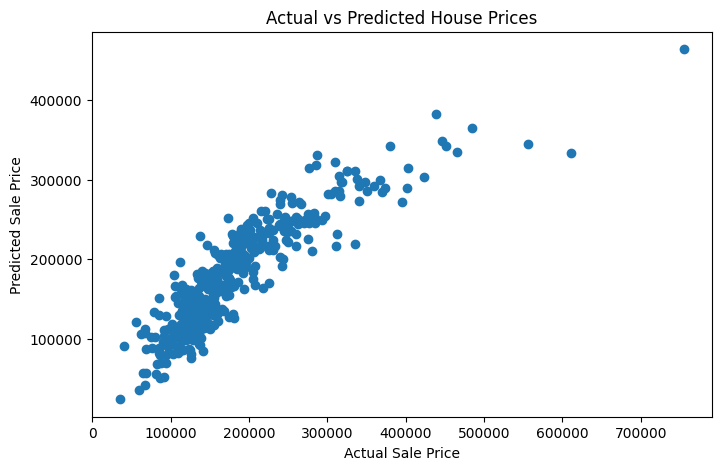

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel('Actual Sale Price')
plt.ylabel('Predicted Sale Price')
plt.title('Actual vs Predicted House Prices')
plt.show()

A Linear Regression model was built using the House Prices dataset from Kaggle to predict house sale prices. Five numerical features were selected: living area, number of bedrooms, number of bathrooms, overall quality, and year built. Missing feature values were handled using median imputation. The dataset was split into training and testing sets, and the model was evaluated using R² Score, MAE, MSE, and RMSE. Different train-test split ratios were also compared to investigate their effect on model performance. Finally, the trained model was used to predict the price of a new house based on its features.